# Tome C5, Chapter 1: Computing with Matrices (Python companion)

Exercises first, solutions at the end. We measure rounding errors, replay the Patriot clock, watch the Hilbert matrix defeat every algorithm while the residual stays tiny, compare three ways of computing $QR$, provoke the worst growth factor of Gaussian elimination, run the $QR$ algorithm with and without shifts, and build a singular value decomposition from scratch by Jacobi rotations.

*Before each solution, predict what the output will look like.*

In [1]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=False, linewidth=110)
rng = np.random.default_rng(1)
u = 2.0**-53

## Exercises

**P1.1 (★) Rounding.** Check that $u=2^{-53}$ is the unit roundoff of Python floats: $1+u$ rounds to $1$ but $1+2u$ does not. Then replay the Patriot clock: chop $1/10$ after $23$ binary places, compute the error per tenth of a second and after $100$ hours, and how far a Scud flying at $1676$ m/s travels meanwhile. Finally redo Exercise 1.1 in single precision.

**P1.2 (★) Hilbert matrices.** Compute $\kappa(H_n)$ for $n=4,\dots,12$ and compare with the lower bound $16^{n-1}/(2n-1)$ of Exercise 1.7 and with $e^{3.53n}$. Solve $H_{10}y=H_{10}\mathbf 1$ and report the forward error and the relative residual. Which of the two does Theorem 1.5 control, and which does backward stability control?

**P1.3 (★★) Three QR factorisations.** Implement classical Gram–Schmidt, modified Gram–Schmidt and Householder $QR$ (Section 1.4) from scratch. On matrices $A=U\Sigma V^{\mathsf T}$ with prescribed condition numbers $10^1,\dots,10^{14}$, plot the loss of orthogonality $\|\hat Q^{\mathsf T}\hat Q-I\|$ against $\kappa(A)$. Check Läuchli's example (Exercise 1.6).

**P1.4 (★★) Backward error of Householder QR.** For random $A$ of sizes up to $200\times100$, measure the backward error $\max_j\|a_j-\hat Q\hat r_j\|/\|a_j\|$ of your Householder $QR$ (with $\hat Q$ built from the computed reflections) and compare with $u$ and with the bound of Theorem 1.13. Then solve a least squares problem with $\kappa(A)=10^{8}$ by $QR$ and by the normal equations.

**P1.5 (★) Growth.** Implement Gaussian elimination with partial pivoting. Verify that Wilkinson's matrix $W_n$ (Proposition 1.11) has growth $2^{n-1}$, that $\|W_n^{-1}\|_\infty=1$ (Exercise 1.5), and see what happens to the solution of $W_{60}x=b$. Then estimate the typical growth factor on random Gaussian matrices for $n=8,\dots,256$. Replay Exercise 1.4.

**P1.6 (★★) The QR algorithm.** Run the unshifted $QR$ algorithm on a symmetric matrix with eigenvalues $10,7,6,3,1$ and check that $|(A_k)_{l+1,l}|$ decays like $|\lambda_{l+1}/\lambda_l|^k$ (Theorem 1.18, Figure 1.2). Then add Wilkinson shifts and deflation, reduce first to tridiagonal form, and count the iterations needed per eigenvalue for random symmetric matrices of size $50$.

**P1.7 (★★) An SVD from scratch.** Implement the classical Jacobi method of Theorem 1.21 and check the decay of $\operatorname{off}(S)$ against $(1-\frac2{n(n-1)})^k$. Then implement the one-sided Jacobi SVD of Hestenes, compare its singular values with the library, and run it on the matrix of Exercise 1.11.

## Solutions

### P1.1

In [2]:
print("1 + u == 1:", 1.0 + u == 1.0, "   1 + 2u == 1:", 1.0 + 2*u == 1.0, "   u =", u)
chopped = math.floor(0.1 * 2**23) / 2**23
err = 0.1 - chopped
tenths = 100 * 3600 * 10
print(f"error per tenth: {err:.3e} s; after 100 hours: {err*tenths:.4f} s; Scud distance: {err*tenths*1676:.0f} m")
x32 = np.float32
s = x32(0)
for k in range(1, 10**6 + 1):
    s = x32(s + x32(1) / x32(k * k))
t = x32(0)
for k in range(10**6, 0, -1):
    t = x32(t + x32(1) / x32(k * k))
exact = math.pi**2 / 6 - sum(1 / k**2 for k in range(10**6 + 1, 10**7)) - 1e-7  # tail beyond 1e7 is about 1e-7
print(f"single precision, increasing k: {s:.7f}; decreasing k: {t:.7f}; exact: {exact:.7f}")
print("terms lost when added to 1.64 start near k =", int(1 / math.sqrt(2**-24 * 1.64)))

1 + u == 1: True    1 + 2u == 1: False    u = 1.1102230246251565e-16
error per tenth: 9.537e-08 s; after 100 hours: 0.3433 s; Scud distance: 575 m


single precision, increasing k: 1.6447253; decreasing k: 1.6449330; exact: 1.6449331
terms lost when added to 1.64 start near k = 3198


The clock error, $0.3433$ s after $100$ hours, is exactly the figure of the government report, and a Scud covers more than half a kilometre in that time. In single precision the forward sum stalls once $1/k^2$ drops below half a unit in the last place of $1.64$; summing from the small end loses almost nothing. The order of a sum matters, as Exercise 1.1 predicts.

### P1.2

In [3]:
def hilbert(n):
    i = np.arange(1, n + 1)
    return 1.0 / (i[:, None] + i[None, :] - 1)
for n in range(4, 13):
    k = np.linalg.cond(hilbert(n))
    print(f"n={n:2d}  cond={k:.3e}  lower bound 16^(n-1)/(2n-1)={16.0**(n-1)/(2*n-1):.2e}  e^(3.53n)={math.exp(3.53*n):.2e}")
H = hilbert(10); x = np.ones(10); b = H @ x
y = np.linalg.solve(H, b)
print("H10: forward error", np.linalg.norm(y - x) / np.linalg.norm(x),
      " relative residual", np.linalg.norm(H @ y - b) / (np.linalg.norm(H, 2) * np.linalg.norm(y)))

n= 4  cond=1.551e+04  lower bound 16^(n-1)/(2n-1)=5.85e+02  e^(3.53n)=1.36e+06
n= 5  cond=4.766e+05  lower bound 16^(n-1)/(2n-1)=7.28e+03  e^(3.53n)=4.63e+07
n= 6  cond=1.495e+07  lower bound 16^(n-1)/(2n-1)=9.53e+04  e^(3.53n)=1.58e+09
n= 7  cond=4.754e+08  lower bound 16^(n-1)/(2n-1)=1.29e+06  e^(3.53n)=5.39e+10
n= 8  cond=1.526e+10  lower bound 16^(n-1)/(2n-1)=1.79e+07  e^(3.53n)=1.84e+12
n= 9  cond=4.932e+11  lower bound 16^(n-1)/(2n-1)=2.53e+08  e^(3.53n)=6.27e+13
n=10  cond=1.602e+13  lower bound 16^(n-1)/(2n-1)=3.62e+09  e^(3.53n)=2.14e+15
n=11  cond=5.230e+14  lower bound 16^(n-1)/(2n-1)=5.24e+10  e^(3.53n)=7.31e+16
n=12  cond=1.620e+16  lower bound 16^(n-1)/(2n-1)=7.65e+11  e^(3.53n)=2.49e+18
H10: forward error 1.2491119308525048e-05  relative residual 1.3292980852352137e-16


$\kappa(H_{10})\approx1.6\times10^{13}$ and $\kappa(H_{12})\approx1.6\times10^{16}$, as in the text. The forward error is about $10^{-5}$: five correct digits, better than the worst case $u\kappa\approx10^{-3}$ of Theorem 1.5. The residual is of order $u$: the computed $y$ solves a system within rounding distance of $H_{10}y=b$. That is backward stability, and it is all an algorithm can promise; the rest is the condition of the problem. Wilkinson's riddle in one line.

### P1.3

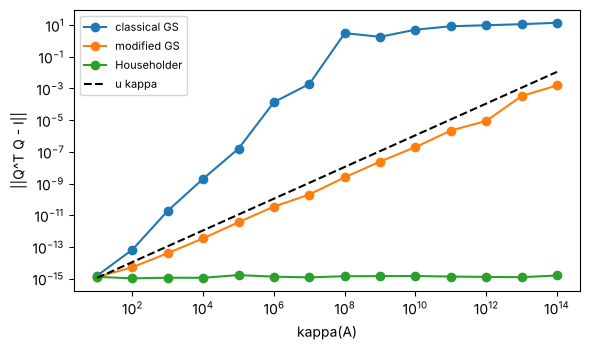

classical q2.q3 = 0.5  q1.q3 = -7.071067811865477e-11
modified q2.q3 = -0.0  q1.q3 = -4.0824829046386295e-11


In [4]:
def cgs(A):
    m, n = A.shape; Q = np.zeros((m, n))
    for j in range(n):
        v = A[:, j] - Q[:, :j] @ (Q[:, :j].T @ A[:, j])
        Q[:, j] = v / np.linalg.norm(v)
    return Q
def mgs(A):
    Q = A.astype(float).copy(); n = A.shape[1]
    for j in range(n):
        Q[:, j] /= np.linalg.norm(Q[:, j])
        for k in range(j + 1, n):
            Q[:, k] -= (Q[:, j] @ Q[:, k]) * Q[:, j]
    return Q
def house(A):
    # returns the list of Householder vectors and R
    R = A.astype(float).copy(); m, n = R.shape; V = []
    for k in range(n):
        x = R[k:, k].copy()
        s = 1.0 if x[0] >= 0 else -1.0
        v = x.copy(); v[0] += s * np.linalg.norm(x)
        beta = 2.0 / (v @ v)
        R[k:, k:] -= beta * np.outer(v, v @ R[k:, k:])
        R[k + 1:, k] = 0.0
        V.append(v)
    return V, np.triu(R[:n, :])
def apply_Q(V, X):          # Q X with Q = P_1 ... P_n
    X = X.astype(float).copy()
    for k in reversed(range(len(V))):
        v = V[k]; X[k:] -= (2.0 / (v @ v)) * np.outer(v, v @ X[k:])
    return X
def apply_QT(V, X):
    X = X.astype(float).copy()
    for k in range(len(V)):
        v = V[k]; X[k:] -= (2.0 / (v @ v)) * np.outer(v, v @ X[k:])
    return X
def with_cond(m, n, kappa):
    U, _ = np.linalg.qr(rng.standard_normal((m, n))); W, _ = np.linalg.qr(rng.standard_normal((n, n)))
    return U @ np.diag(np.logspace(0, -math.log10(kappa), n)) @ W.T
kap = [10.0**e for e in range(1, 15)]
res = {"classical GS": [], "modified GS": [], "Householder": []}
for k in kap:
    A = with_cond(60, 30, k)
    for name, Q in [("classical GS", cgs(A)), ("modified GS", mgs(A)),
                    ("Householder", apply_Q(house(A)[0], np.eye(60)[:, :30]))]:
        res[name].append(np.linalg.norm(Q.T @ Q - np.eye(30), 2))
plt.figure(figsize=(6, 3.6))
for name, r in res.items():
    plt.loglog(kap, r, "o-", label=name)
plt.loglog(kap, [u * k for k in kap], "k--", label="u kappa")
plt.xlabel("kappa(A)"); plt.ylabel("||Q^T Q - I||"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()
e = 1e-10
A = np.array([[1, 1, 1], [e, 0, 0], [0, e, 0], [0, 0, e]])
for name, Q in [("classical", cgs(A)), ("modified", mgs(A))]:
    print(name, "q2.q3 =", round(Q[:, 1] @ Q[:, 2], 12), " q1.q3 =", Q[:, 0] @ Q[:, 2])

Classical Gram–Schmidt loses orthogonality like $u\kappa^2$ and is useless beyond $\kappa\approx10^8$; modified Gram–Schmidt like $u\kappa$; Householder stays at the level of $u$ whatever $\kappa$, as Theorem 1.13 predicts. On Läuchli's matrix classical Gram–Schmidt returns $\hat q_2^{\mathsf T}\hat q_3=\frac12$ exactly, and the modified version gives $0$ there and $-\varepsilon/\sqrt6$ for $\hat q_1^{\mathsf T}\hat q_3$, as computed by hand in the solution of Exercise 1.6.

### P1.4

In [5]:
for (m, n) in [(20, 10), (100, 50), (200, 100)]:
    A = rng.standard_normal((m, n))
    V, Rh = house(A)
    QR = apply_Q(V, np.vstack([Rh, np.zeros((m - n, n))]))
    be = max(np.linalg.norm(A[:, j] - QR[:, j]) / np.linalg.norm(A[:, j]) for j in range(n))
    eta = (10 * m + 20) * u
    print(f"{m}x{n}: backward error {be:.2e} = {be/u:.1f} u   (proved bound n*eta/(1-n*eta) = {n*eta/(1-n*eta):.1e})")
A = with_cond(100, 20, 1e8); xtrue = rng.standard_normal(20); b = A @ xtrue
V, Rh = house(A); c = apply_QT(V, b[:, None])[:20, 0]
x_qr = np.linalg.solve(Rh, c)           # triangular solve
x_ne = np.linalg.solve(A.T @ A, A.T @ b)
print("kappa = 1e8, relative error by QR:", np.linalg.norm(x_qr - xtrue) / np.linalg.norm(xtrue),
      "  by normal equations:", np.linalg.norm(x_ne - xtrue) / np.linalg.norm(xtrue))

20x10: backward error 6.59e-16 = 5.9 u   (proved bound n*eta/(1-n*eta) = 2.4e-13)
100x50: backward error 1.12e-15 = 10.1 u   (proved bound n*eta/(1-n*eta) = 5.7e-12)
200x100: backward error 1.42e-15 = 12.8 u   (proved bound n*eta/(1-n*eta) = 2.2e-11)
kappa = 1e8, relative error by QR: 9.540877303257681e-10   by normal equations: 0.17962975934612962


The measured backward error is a few units of $u$, far below the crude bound we proved (whose constant $10m+20$ was not optimised). With $\kappa=10^8$, $QR$ keeps about eight digits and the normal equations about zero: forming $A^{\mathsf T}A$ squares the condition number to $10^{16}$, as Corollary 1.14 and Exercise 1.3 explain.

### P1.5

In [6]:
def gepp(A):
    A = A.astype(float).copy(); n = len(A); perm = np.arange(n); amax = np.abs(A).max(); g = amax
    for k in range(n - 1):
        p = k + np.argmax(np.abs(A[k:, k]))     # argmax returns the first maximum: ties keep row k
        A[[k, p]] = A[[p, k]]; perm[[k, p]] = perm[[p, k]]
        A[k + 1:, k] /= A[k, k]
        A[k + 1:, k + 1:] -= np.outer(A[k + 1:, k], A[k, k + 1:])
        g = max(g, np.abs(A[k + 1:, k + 1:]).max())
    return A, perm, g / amax
def solve_lu(LU, perm, b):
    n = len(LU); y = b[perm].astype(float)
    for i in range(n): y[i] -= LU[i, :i] @ y[:i]
    for i in reversed(range(n)): y[i] = (y[i] - LU[i, i + 1:] @ y[i + 1:]) / LU[i, i]
    return y
def W(n):
    M = np.eye(n) - np.tril(np.ones((n, n)), -1); M[:, -1] = 1; return M
for n in [5, 10, 20, 40]:
    print(f"n={n}: growth {gepp(W(n))[2]:.4g} = 2^{math.log2(gepp(W(n))[2]):.0f};  ||W^-1||_inf = {np.abs(np.linalg.inv(W(n))).sum(1).max():.6f}")
n = 60; Wn = W(n); xt = rng.standard_normal(n); b = Wn @ xt
LU, perm, g = gepp(Wn); x = solve_lu(LU, perm, b)
print("W_60: kappa_inf =", np.abs(Wn).sum(1).max() * np.abs(np.linalg.inv(Wn)).sum(1).max(), " relative error of GEPP:", np.linalg.norm(x - xt) / np.linalg.norm(xt))
for n in [8, 32, 128, 256]:
    gs = [gepp(rng.standard_normal((n, n)))[2] for _ in range(20 if n < 200 else 5)]
    print(f"random n={n}: median growth {np.median(gs):.2f}  (n^(2/3) = {n**(2/3):.1f})")
eps = 1e-20; A = np.array([[eps, 1.0], [1.0, 1.0]]); b = np.array([1.0, 2.0])
l21 = 1 / eps; u22 = 1 - l21; y2 = 2 - l21; x2 = y2 / u22; x1 = (1 - x2) / eps
print("no pivoting:", (x1, x2), "  partial pivoting:", solve_lu(*gepp(A)[:2], b), "  kappa:", np.linalg.cond(A))

n=5: growth 16 = 2^4;  ||W^-1||_inf = 1.000000
n=10: growth 512 = 2^9;  ||W^-1||_inf = 1.000000
n=20: growth 5.243e+05 = 2^19;  ||W^-1||_inf = 1.000000
n=40: growth 5.498e+11 = 2^39;  ||W^-1||_inf = 1.000000
W_60: kappa_inf = 60.0  relative error of GEPP: 0.08597686598082939
random n=8: median growth 1.29  (n^(2/3) = 4.0)
random n=32: median growth 2.84  (n^(2/3) = 10.1)
random n=128: median growth 6.13  (n^(2/3) = 25.4)


random n=256: median growth 8.59  (n^(2/3) = 40.3)
no pivoting: (0.0, 1.0)   partial pivoting: [1. 1.]   kappa: 2.6180339887498953


The growth is exactly $2^{n-1}$ on $W_n$, which is perfectly conditioned ($\kappa_\infty=n$), and for $n=60$ the computed solution is garbage: Gaussian elimination with partial pivoting is not backward stable in the worst case. On random matrices the growth stays small, of the order of $n^{2/3}$ reported by Trefethen and Schreiber, which is why everybody uses it anyway.

### P1.6

In [7]:
lam = np.array([10., 7., 6., 3., 1.])
Q, _ = np.linalg.qr(np.random.default_rng(1).standard_normal((5, 5)))
A = Q @ np.diag(lam) @ Q.T
Ak = A.copy(); sub = []
for k in range(61):
    sub.append([abs(Ak[l + 1, l]) for l in range(4)])
    q, r = np.linalg.qr(Ak); d = np.sign(np.diag(r)); Ak = (r.T * d).T @ (q * d)
sub = np.array(sub)
for l in range(4):
    rate = (sub[30, l] / sub[20, l]) ** 0.1 if sub[30, l] > 1e-300 else float("nan")
    print(f"l={l+1}: observed rate {rate:.4f}, predicted |lambda_l+1/lambda_l| = {lam[l+1]/lam[l]:.4f}")
print("diagonal after 60 steps:", np.round(np.diag(Ak), 10))
def wilkinson_shift(T):
    a, b, c = T[-2, -2], T[-1, -2], T[-1, -1]; d = (a - c) / 2
    return c - (1 if d >= 0 else -1) * b * b / (abs(d) + math.hypot(d, b))
Ak = A.copy(); tr = []
for k in range(6):
    tr.append(abs(Ak[4, 3])); mu = wilkinson_shift(Ak)
    q, r = np.linalg.qr(Ak - mu * np.eye(5)); Ak = r @ q + mu * np.eye(5)
print("Wilkinson shift on the full 5x5:", ["%.1e" % t for t in tr])
def tridiag(A):
    A = A.copy(); n = len(A)
    for k in range(n - 2):
        x = A[k + 1:, k].copy(); v = x.copy(); v[0] += (1 if x[0] >= 0 else -1) * np.linalg.norm(x)
        if v @ v == 0: continue
        P = np.eye(n - k - 1) - 2 * np.outer(v, v) / (v @ v)
        A[k + 1:, :] = P @ A[k + 1:, :]; A[:, k + 1:] = A[:, k + 1:] @ P
    return A
def eig_qr(A, tol=1e-14):
    T = tridiag(A); n = len(T); eigs = []; its = 0
    while n > 1:
        if abs(T[n - 1, n - 2]) < tol * (abs(T[n - 1, n - 1]) + abs(T[n - 2, n - 2])):
            eigs.append(T[n - 1, n - 1]); T = T[:n - 1, :n - 1]; n -= 1; continue
        mu = wilkinson_shift(T); q, r = np.linalg.qr(T - mu * np.eye(n)); T = r @ q + mu * np.eye(n); its += 1
    eigs.append(T[0, 0])
    return np.sort(eigs), its
tot = 0
for trial in range(5):
    B = rng.standard_normal((50, 50)); B = B + B.T
    ev, its = eig_qr(B); tot += its
    assert np.allclose(ev, np.linalg.eigvalsh(B), atol=1e-10)
print("tridiagonal + Wilkinson shifts, n=50: average QR steps per eigenvalue", tot / (5 * 49))

l=1: observed rate 0.7000, predicted |lambda_l+1/lambda_l| = 0.7000
l=2: observed rate 0.8572, predicted |lambda_l+1/lambda_l| = 0.8571
l=3: observed rate 0.5000, predicted |lambda_l+1/lambda_l| = 0.5000
l=4: observed rate 0.3333, predicted |lambda_l+1/lambda_l| = 0.3333
diagonal after 60 steps: [10.  7.  6.  3.  1.]
Wilkinson shift on the full 5x5: ['1.1e+00', '1.1e+00', '9.5e-01', '4.6e-02', '3.1e-07', '1.6e-18']
tridiagonal + Wilkinson shifts, n=50: average QR steps per eigenvalue 2.126530612244898


Each subdiagonal entry decays at exactly the rate of Theorem 1.18; the pair $7,6$ is the slow one. With Wilkinson shifts the last entry collapses in five steps on the full matrix, and on tridiagonal matrices with deflation the whole spectrum of a $50\times50$ matrix comes out in well under two $QR$ steps per eigenvalue.

### P1.7

In [8]:
def off(S): return (S**2).sum() - (np.diag(S)**2).sum()
def jacobi_eig(S, steps):
    S = S.copy(); n = len(S); hist = [off(S)]
    for _ in range(steps):
        M = np.abs(S - np.diag(np.diag(S))); p, q = np.unravel_index(np.argmax(M), M.shape)
        if M[p, q] == 0: break
        th = 0.5 * math.atan2(2 * S[p, q], S[q, q] - S[p, p])
        c, s = math.cos(th), math.sin(th)
        J = np.eye(n); J[p, p] = J[q, q] = c; J[p, q] = s; J[q, p] = -s
        S = J.T @ S @ J; hist.append(off(S))
    return S, hist
n = 8; B = rng.standard_normal((n, n)); S0 = B + B.T
S, hist = jacobi_eig(S0, 150)
bound = [hist[0] * (1 - 2 / (n * (n - 1)))**k for k in range(len(hist))]
print("Jacobi: off after 28, 56, 150 steps:", hist[28], hist[56], hist[-1], " bound after 150:", bound[-1])
print("eigenvalues match:", np.allclose(np.sort(np.diag(S)), np.linalg.eigvalsh(S0)))
def jacobi_svd(A, sweeps=30, tol=1e-15):
    U = A.astype(float).copy(); n = U.shape[1]; V = np.eye(n)
    for _ in range(sweeps):
        rot = 0
        for p in range(n - 1):
            for q in range(p + 1, n):
                a, b, g = U[:, p] @ U[:, p], U[:, q] @ U[:, q], U[:, p] @ U[:, q]
                if abs(g) <= tol * math.sqrt(a * b): continue
                rot += 1
                th = 0.5 * math.atan2(2 * g, b - a); c, s = math.cos(th), math.sin(th)
                Up, Uq = U[:, p].copy(), U[:, q].copy(); U[:, p], U[:, q] = c * Up - s * Uq, s * Up + c * Uq
                Vp, Vq = V[:, p].copy(), V[:, q].copy(); V[:, p], V[:, q] = c * Vp - s * Vq, s * Vp + c * Vq
        if rot == 0: break
    sig = np.linalg.norm(U, axis=0)
    return sig, U / sig, V
A = rng.standard_normal((30, 12))
sig, Uj, Vj = jacobi_svd(A)
print("one-sided Jacobi vs library:", np.max(np.abs(np.sort(sig) - np.sort(np.linalg.svd(A, compute_uv=False)))),
      "  reconstruction:", np.abs(Uj * sig @ Vj.T - A).max())
d = 1e-9
Asq = np.array([[1, 1], [d, 0], [0, d]])
print("delta = 1e-9: sigma_2 via eig(A^T A):", np.sqrt(max(np.linalg.eigvalsh(Asq.T @ Asq)[0], 0)),
      "  via one-sided Jacobi:", min(jacobi_svd(Asq)[0]))

Jacobi: off after 28, 56, 150 steps: 0.2171307645058107 6.057751562593694e-06 0.0  bound after 150: 0.5145230458797637
eigenvalues match: True
one-sided Jacobi vs library: 3.552713678800501e-15   reconstruction: 2.886579864025407e-15
delta = 1e-9: sigma_2 via eig(A^T A): 0.0   via one-sided Jacobi: 1e-09


The off-diagonal mass falls far faster than the guaranteed factor $1-\frac2{n(n-1)}$ per rotation, and becomes quadratically convergent at the end (Schönhage's theorem). Twenty lines of one-sided Jacobi reproduce the library's singular values to rounding level. On the matrix of Exercise 1.11, $\sigma_2=\delta=10^{-9}$: the eigenvalues of the computed $A^{\mathsf T}A$ give $0$ (or noise), while one-sided Jacobi, which never forms $A^{\mathsf T}A$, returns $\delta$ to full relative precision.